# From time dilation and relativistic momentum to $E=\gamma mc^2$

### A complete, step-by-step mathematical derivation with diagrams, graphs, and numerical experiments

**Route through the argument**

$$
\text{Time dilation}
\;\longrightarrow\;
\gamma
\;\longrightarrow\;
p=\gamma mv
\;\longrightarrow\;
dK=v\,dp
\;\longrightarrow\;
K=(\gamma-1)mc^2
\;\longrightarrow\;
E=\gamma mc^2.
$$

The final arrow needs special care: **integrating work establishes the kinetic energy but does not, by itself, determine the energy of a body at rest**. To establish the rest-energy term $mc^2$, we use the Lorentz-covariant energy–momentum four-vector. The notebook shows both parts, rather than silently inserting the integration constant.

All derivations below concern an ordinary particle with **nonzero rest mass**, moving in a straight line in an inertial reference frame, with $|v|<c$. When calculating work, the force is taken parallel to motion.

No pandas, SciPy, or SymPy is required for the examples. The figures are saved automatically to the `figures/` subfolder.

## 1. Symbols: use as few as possible

| Symbol | Meaning | Units |
|---|---|---|
| $m$ | Invariant (rest) mass of the particle | kg |
| $v$ | Speed in the chosen inertial frame | m/s |
| $c$ | Speed of light in vacuum | m/s |
| $t$ | Coordinate time measured in that frame | s |
| $\tau$ | Proper time carried by the moving particle | s |
| $\gamma$ | Lorentz factor, which depends on $v$ | no units |
| $p$ | Relativistic momentum along the motion | kg m/s |
| $F$ | Force parallel to motion | N |
| $K$ | Kinetic energy; **zero at rest** | J |
| $E$ | Total relativistic energy, including rest energy | J |

Only in a substitution or definite integral will we temporarily use a new dummy variable. This avoids confusing the final velocity $v$ with the speed being integrated over.

The two fundamental identities are

\[
\gamma=\frac{1}{\sqrt{1-v^2/c^2}}, \qquad \frac{dt}{d\tau}=\gamma.
\]

In [1]:
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

c = 299_792_458.0   # exact defined speed of light in SI (m/s)
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (9.4, 5.4),
    'figure.dpi': 105,
    'font.size': 11,
    'axes.grid': True,
    'grid.alpha': 0.22,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

def gamma(beta):
    # Lorentz factor, with beta = speed/c and 0 <= beta < 1.
    return 1 / np.sqrt(1 - np.asarray(beta)**2)

def save_plot(name):
    # Save the current plot separately as PNG, as well as displaying it.
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches='tight')
    plt.show()

print(f'c = {c:,.0f} m/s')
print('Only NumPy and Matplotlib are used for computation and plotting.')

c = 299,792,458 m/s
Only NumPy and Matplotlib are used for computation and plotting.


## 2. Where $\gamma$ comes from: a moving light clock

Consider two mirrors a distance $L$ apart **perpendicular** to the direction of motion. Light bounces from the lower mirror to the upper mirror. The clock travels horizontally with speed $v$.

- **In the clock's own frame:** light goes straight up through distance $L$, so the one-way time is $\Delta\tau/2=L/c$.
- **In the laboratory frame:** during one upward light trip the clock moves horizontally through $v\Delta t/2$. The light travels diagonally through distance $c\Delta t/2$.

The three distances make a right triangle. Pythagoras gives

$$
\left(\frac{c\Delta t}{2}\right)^2
=
L^2+\left(\frac{v\Delta t}{2}\right)^2.
$$

Substitute $L=c\Delta\tau/2$:

$$
\frac{c^2\Delta t^2}{4}
=
\frac{c^2\Delta\tau^2}{4}
+\frac{v^2\Delta t^2}{4}.
$$

Multiply by $4$, then collect the terms containing $\Delta t$:

$$
(c^2-v^2)\Delta t^2=c^2\Delta\tau^2.
$$

Divide by $c^2$ and take the positive square root:

$$
\Delta t=\frac{\Delta\tau}{\sqrt{1-v^2/c^2}}=\gamma\Delta\tau.
$$

Thus $\gamma$ describes how laboratory coordinate time compares with the **proper time of the clock**. It does not by itself prove a formula for momentum or energy; the relativity of momentum also requires the Lorentz-covariant definition of momentum, developed next.

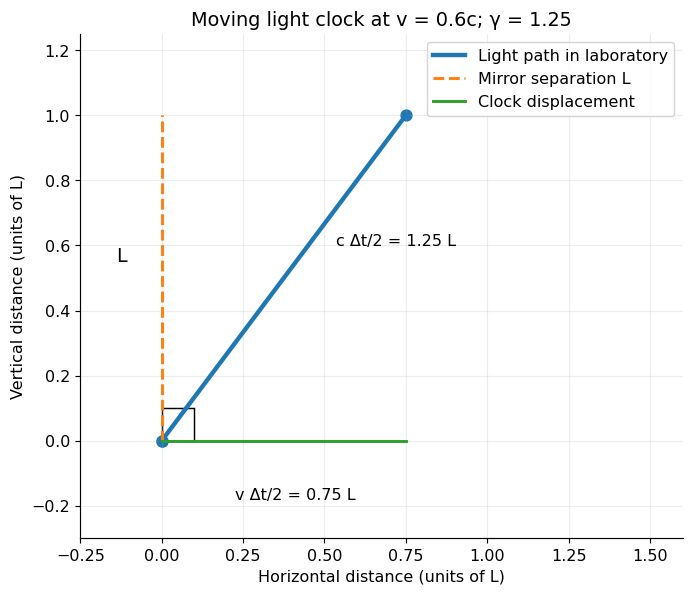

In [2]:
# Light-clock triangle. Normalise c = 1 and L = 1 for geometry only.
b = 0.60
g = gamma(b)
L = 1.0
horizontal = b * g * L       # v * (Δt/2)
diagonal = g * L             # c * (Δt/2)

fig, ax = plt.subplots(figsize=(8, 5.8))
ax.plot([0, horizontal], [0, L], lw=3, label='Light path in laboratory')
ax.plot([0, 0], [0, L], '--', lw=2, label='Mirror separation L')
ax.plot([0, horizontal], [0, 0], lw=2, label='Clock displacement')
ax.scatter([0, horizontal, 0], [0, L, 0], s=55)
ax.add_patch(plt.Rectangle((0, 0), 0.10, 0.10, fill=False))
ax.annotate(f'c Δt/2 = {diagonal:.2f} L', (horizontal/2, L/2),
            xytext=(horizontal/2+0.16, L/2+0.10))
ax.annotate(f'v Δt/2 = {horizontal:.2f} L', (horizontal/2, 0),
            xytext=(horizontal/2-0.15, -0.18))
ax.text(-0.14, 0.55, 'L', fontsize=13)
ax.set(xlabel='Horizontal distance (units of L)',
       ylabel='Vertical distance (units of L)',
       title=f'Moving light clock at v = {b:.1f}c; γ = {g:.2f}',
       xlim=(-0.25, 1.6), ylim=(-0.3, 1.25))
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='upper right')
save_plot('01_moving_light_clock.png')

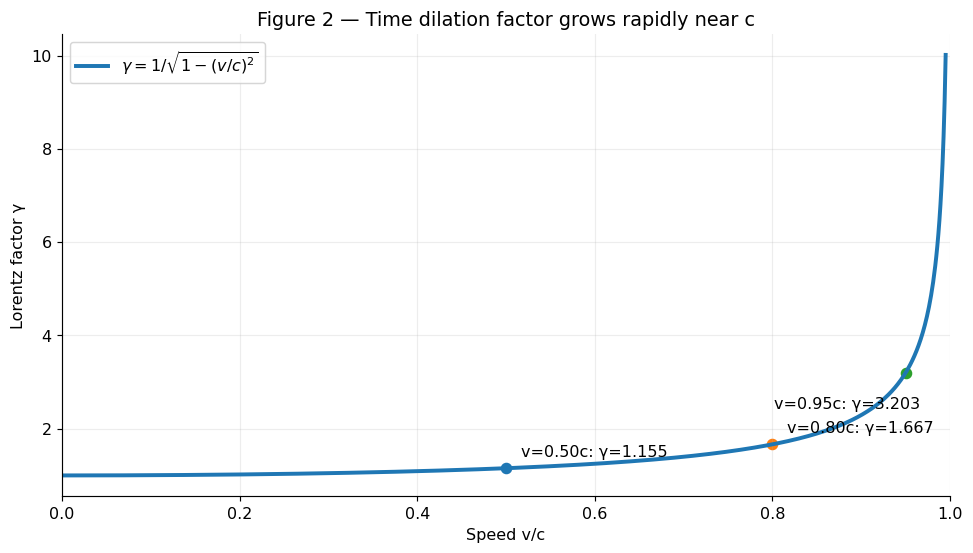

In [3]:
beta = np.linspace(0, 0.995, 850)
fig, ax = plt.subplots()
ax.plot(beta, gamma(beta), lw=2.7, label=r'$\gamma=1/\sqrt{1-(v/c)^2}$')
for b in [0.5, 0.8, 0.95]:
    ax.scatter([b], [gamma(b)], s=48)
    ax.annotate(f'v={b:.2f}c: γ={gamma(b):.3f}', (b, gamma(b)),
                xytext=(-90,-25) if b > .9 else (10,8),
                textcoords='offset points')
ax.set(xlabel='Speed v/c', ylabel='Lorentz factor γ',
       title='Figure 2 — Time dilation factor grows rapidly near c',
       xlim=(0, 1))
ax.legend(loc='upper left')
save_plot('02_lorentz_factor.png')

## 3. From time dilation to relativistic momentum

The spacetime interval along a particle's trajectory satisfies

$$
c^2d\tau^2=c^2dt^2-dx^2
\quad\Rightarrow\quad
d\tau=dt\sqrt{1-v^2/c^2}=\frac{dt}{\gamma},
$$

because $v=dx/dt$. Rearrange:

$$
\frac{dt}{d\tau}=\gamma.
$$

In special relativity, the momentum of a particle is the **spatial component of its four-momentum**. It uses the rate of change of position with respect to proper time:

$$
p=m\frac{dx}{d\tau}.
$$

Apply the chain rule:

$$
\frac{dx}{d\tau}
=\frac{dx}{dt}\frac{dt}{d\tau}
=v\gamma.
$$

Therefore

$$
p=\gamma mv=\frac{mv}{\sqrt{1-v^2/c^2}}.
$$

At low velocities $\gamma\approx1$, so this reduces to Newtonian momentum $p\approx mv$. **Why this construction?** Four-momentum transforms consistently under Lorentz transformations and obeys the relativistic conservation laws. Simply observing that clocks dilate would *not* independently justify attaching a factor of $\gamma$ to Newton's formula.

For a fixed nonzero rest mass, the momentum grows without bound as $v$ approaches $c$ from below. It is the momentum, not the rest mass, that contains the factor $\gamma$.

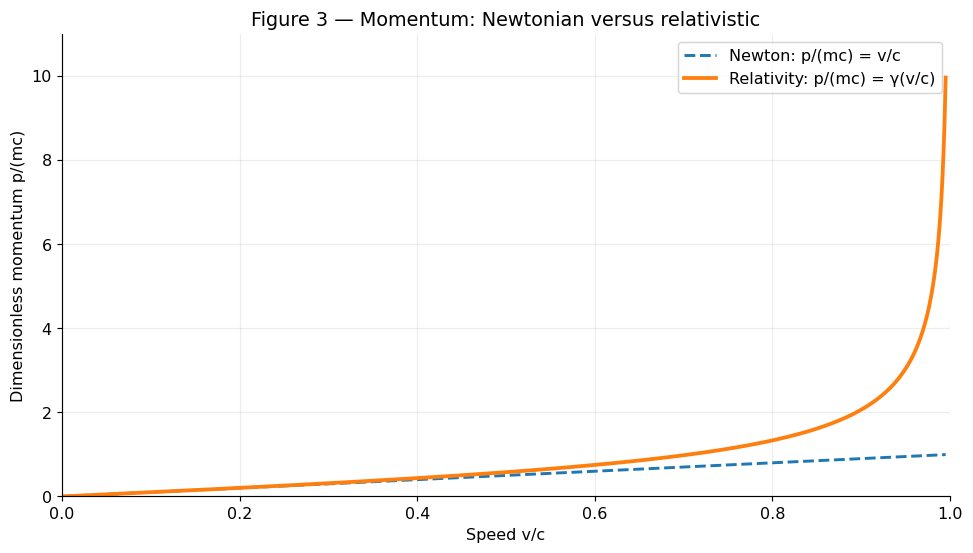

In [4]:
# Compare p/(mc). Classical p/(mc)=v/c. Relativistic p/(mc)=γ(v/c).
fig, ax = plt.subplots()
ax.plot(beta, beta, '--', lw=2, label='Newton: p/(mc) = v/c')
ax.plot(beta, gamma(beta)*beta, lw=2.6,
        label='Relativity: p/(mc) = γ(v/c)')
ax.set(xlabel='Speed v/c', ylabel='Dimensionless momentum p/(mc)',
       title='Figure 3 — Momentum: Newtonian versus relativistic',
       xlim=(0, 1), ylim=(0, 11))
ax.legend()
save_plot('03_momentum_comparison.png')

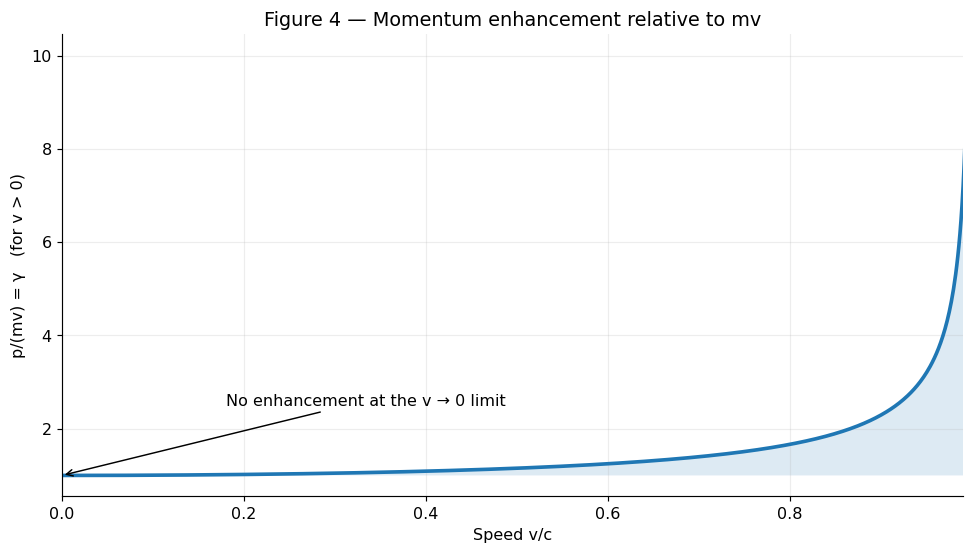

In [5]:
fig, ax = plt.subplots()
ax.plot(beta, gamma(beta), lw=2.5)
ax.fill_between(beta, 1, gamma(beta), alpha=.15)
ax.set(xlabel='Speed v/c', ylabel='p/(mv) = γ   (for v > 0)',
       title='Figure 4 — Momentum enhancement relative to mv',
       xlim=(0, .99))
ax.annotate('No enhancement at the v → 0 limit', xy=(0, 1),
            xytext=(.18, 2.5), arrowprops=dict(arrowstyle='->'))
save_plot('04_momentum_dilation_factor.png')

---

## 4. Why mechanical work is $dK=v\,dp$

Define force as the rate of change of momentum:

$$
F=\frac{dp}{dt}.
$$

An infinitesimal amount of work done by a force parallel to the displacement is

$$
dK=F\,dx.
$$

Insert the momentum definition of force:

$$
dK=\frac{dp}{dt}\,dx.
$$

Since velocity is $v=dx/dt$, we have $dx=v\,dt$. Thus

$$
\begin{aligned}
dK&=\frac{dp}{dt}(v\,dt)\\[4pt]
&=v\,dp.
\end{aligned}
$$

**This is the central link between momentum and kinetic energy:**

$$
dK=v\,dp.
$$

Notice the difference between $v\,dp$ and $p\,dv$. They are **not the same differential** in general. Later we will derive the correct integration-by-parts connection between their areas.


---

## 5. Differentiate the relativistic momentum: every algebraic step

Start with

$$
p=\gamma mv=m v\left(1-\frac{v^2}{c^2}\right)^{-1/2}.
$$

We first need the derivative of $\gamma$ with respect to $v$. Treat $m$ and $c$ as constants.

**Step 1 — Write the Lorentz factor as a power:**

$$
\gamma(v)=\left(1-\frac{v^2}{c^2}\right)^{-1/2}.
$$

**Step 2 — Differentiate the outside power (the chain rule):**

$$
\frac{d\gamma}{dv}
=-\frac12\left(1-\frac{v^2}{c^2}\right)^{-3/2}
\frac{d}{dv}\left(1-\frac{v^2}{c^2}\right).
$$

**Step 3 — Differentiate the inside:**

$$
\frac{d}{dv}\left(1-\frac{v^2}{c^2}\right)
=0-\frac{2v}{c^2}=-\frac{2v}{c^2}.
$$

**Step 4 — Multiply:**

$$
\begin{aligned}
\frac{d\gamma}{dv}
&=-\frac12\left(1-\frac{v^2}{c^2}\right)^{-3/2}
\left(-\frac{2v}{c^2}\right)\\[4pt]
&=\frac{v}{c^2}\left(1-\frac{v^2}{c^2}\right)^{-3/2}.
\end{aligned}
$$

Because $\gamma^3=(1-v^2/c^2)^{-3/2}$, this becomes

$$
\frac{d\gamma}{dv}=\frac{\gamma^3v}{c^2}.
$$

Now differentiate $p=m\gamma v$ using the **product rule**:

$$
\begin{aligned}
\frac{dp}{dv}
&=m\frac{d(\gamma v)}{dv}\\
&=m\left(\gamma\frac{dv}{dv}+v\frac{d\gamma}{dv}\right)\\
&=m\left(\gamma+\frac{\gamma^3v^2}{c^2}\right).
\end{aligned}
$$

Factor out $m\gamma^3$:

$$
\frac{dp}{dv}=m\gamma^3\left(\frac{1}{\gamma^2}+\frac{v^2}{c^2}\right).
$$

From the definition of $\gamma$,

$$
\frac{1}{\gamma^2}=1-\frac{v^2}{c^2}.
$$

So the bracket becomes $1$, leaving

$$
\frac{dp}{dv}=m\gamma^3.
$$

This $\gamma^3$ factor is for **the derivative of momentum with respect to speed in the direction of motion**. For transverse force and acceleration, the relation differs; it is not a universal scalar 'relativistic mass'.


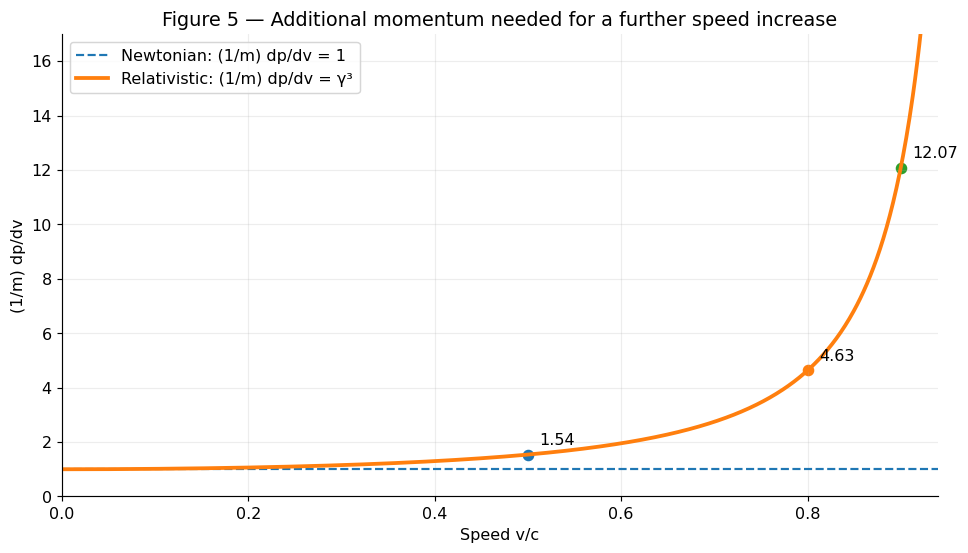

In [6]:
fig, ax = plt.subplots()
ax.plot(beta, np.ones_like(beta), '--', label='Newtonian: (1/m) dp/dv = 1')
ax.plot(beta, gamma(beta)**3, lw=2.6,
        label='Relativistic: (1/m) dp/dv = γ³')
for b in [.5, .8, .9]:
    ax.scatter(b, gamma(b)**3, s=48)
    ax.annotate(f'{gamma(b)**3:.2f}', (b, gamma(b)**3),
                xytext=(8,7), textcoords='offset points')
ax.set(xlabel='Speed v/c', ylabel='(1/m) dp/dv',
       title='Figure 5 — Additional momentum needed for a further speed increase',
       xlim=(0, .94), ylim=(0, 17))
ax.legend()
save_plot('05_momentum_derivative_gamma_cubed.png')

---

## 6. Integrate work to obtain relativistic kinetic energy

We already established

$$
dK=v\,dp.
$$

Because $p$ depends on $v$, the chain rule gives $dp=(dp/dv)\,dv$. Substitute the result $dp/dv=m\gamma^3$:

$$
\begin{aligned}
dK&=v\frac{dp}{dv}\,dv\\[4pt]
&=mv\gamma^3\,dv.
\end{aligned}
$$

From the previous section,

$$
\frac{d\gamma}{dv}=\frac{\gamma^3v}{c^2}.
$$

Multiply **both sides** by $mc^2\,dv$:

$$
mc^2\,d\gamma=mv\gamma^3\,dv.
$$

Comparing this with $dK=mv\gamma^3\,dv$, we see that

$$
dK=mc^2\,d\gamma.
$$

Now integrate between rest and final speed $v$. At rest, $K(0)=0$ and $\gamma(0)=1$:

$$
\begin{aligned}
\int_{K(0)}^{K(v)}dK
&=mc^2\int_{\gamma(0)}^{\gamma(v)}d\gamma,\\[6pt]
K(v)-0&=mc^2\big[\gamma(v)-1\big].
\end{aligned}
$$

Therefore

$$
K=(\gamma-1)mc^2.
$$

**The $-1$ comes from evaluating the lower limit at rest**, where $\gamma=1$. It is not a correction added by hand.

In the familiar speed-only form:

$$
K=mc^2\left(\frac{1}{\sqrt{1-v^2/c^2}}-1\right).
$$

### The same integral with explicit speed limits

Writing the changing velocity inside the integral as $v'$:

$$
K(v)=m\int_0^v \frac{v'}{(1-v'^2/c^2)^{3/2}}\,dv'.
$$

Let $s=1-v'^2/c^2$. Then $ds=-2v'\,dv'/c^2$, or $v'\,dv'=-c^2ds/2$. The lower speed $v'=0$ becomes $s=1$; the upper speed becomes $s=1-v^2/c^2$:

$$
\begin{aligned}
K(v)&=-\frac{mc^2}{2}\int_1^{\,1-v^2/c^2}s^{-3/2}\,ds\\[4pt]
&=-\frac{mc^2}{2}\left[-2s^{-1/2}\right]_1^{\,1-v^2/c^2}\\[4pt]
&=mc^2\left(\frac{1}{\sqrt{1-v^2/c^2}}-1\right).
\end{aligned}
$$

Both derivations are identical mathematically: the first recognises the derivative of $\gamma$, and the second evaluates the integral directly.


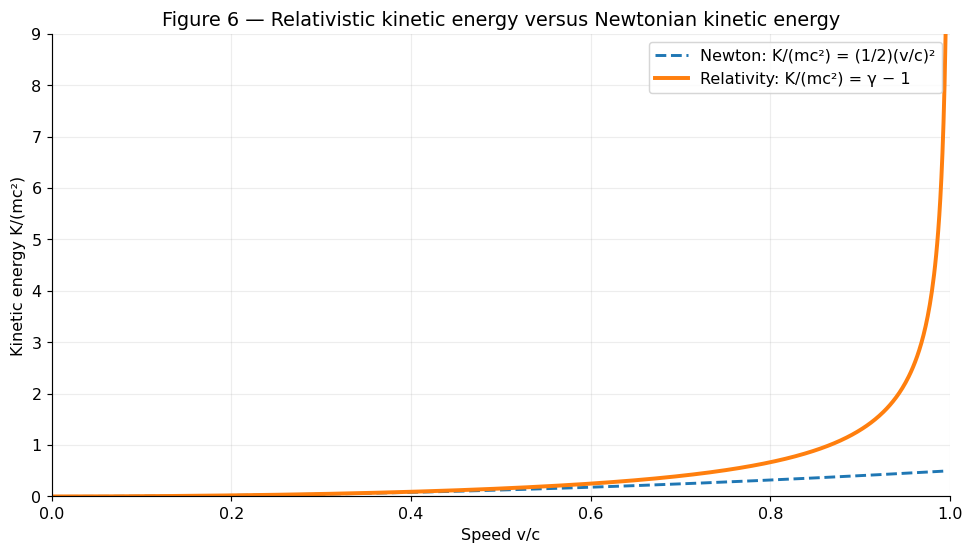

In [7]:
fig, ax = plt.subplots()
ax.plot(beta, .5*beta**2, '--', lw=2,
        label=r'Newton: K/(mc²) = (1/2)(v/c)²')
ax.plot(beta, gamma(beta)-1, lw=2.7,
        label=r'Relativity: K/(mc²) = γ − 1')
ax.set(xlabel='Speed v/c', ylabel='Kinetic energy K/(mc²)',
       title='Figure 6 — Relativistic kinetic energy versus Newtonian kinetic energy',
       xlim=(0, 1), ylim=(0, 9))
ax.legend()
save_plot('06_kinetic_energy_comparison.png')


## 7. What the work integral looks like as an area

The exact work formula is

$$
K=\int_{p=0}^{p=p_f}v\,dp.
$$

This means: plot **velocity on the vertical axis** and **momentum on the horizontal axis**, then calculate the area under the curve up to the final momentum $p_f$. The units are

$$
\left(\frac{\mathrm m}{\mathrm s}\right)
\left(\frac{\mathrm{kg\,m}}{\mathrm s}\right)
=\mathrm{kg\,m^2/s^2}=\mathrm J.
$$

For neat numbers, both axes in the following figure are divided by $c$ or $mc$. The displayed area therefore equals $K/(mc^2)$.

From $p=\gamma mv$, one can solve for velocity in terms of momentum. If the horizontal axis is $p/(mc)$, then

$$
\frac{v}{c}=\frac{p/(mc)}{\sqrt{1+[p/(mc)]^2}}.
$$

We will calculate the area both analytically and by rectangles.


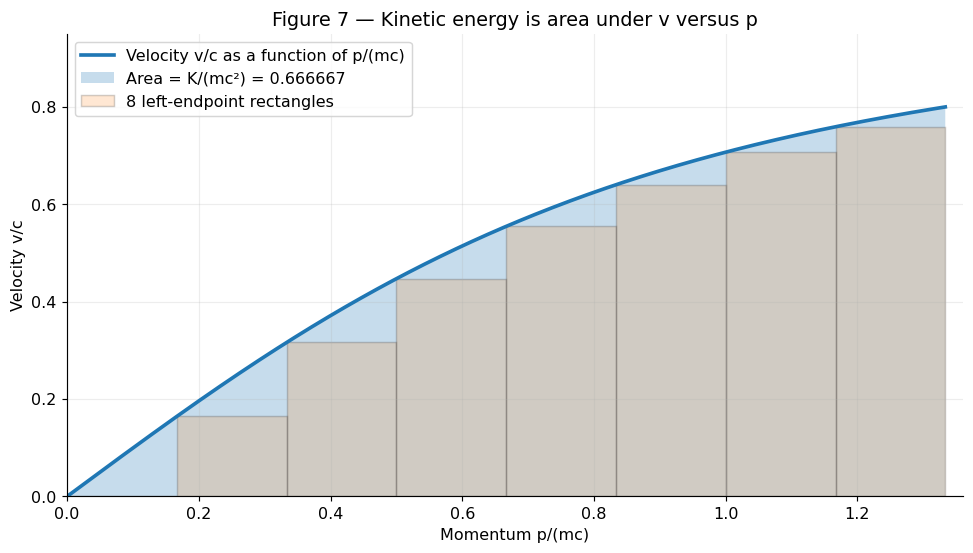

In [8]:
final_beta = 0.8
final_p = gamma(final_beta) * final_beta  # dimensionless p/(mc)
P = np.linspace(0, final_p, 500)
B = P / np.sqrt(1+P**2)
exact_K = gamma(final_beta)-1

fig, ax = plt.subplots()
ax.plot(P, B, lw=2.5, label='Velocity v/c as a function of p/(mc)')
ax.fill_between(P, B, alpha=0.25, label=f'Area = K/(mc²) = {exact_K:.6f}')
N = 8
edges = np.linspace(0, final_p, N+1)
heights = edges[:-1] / np.sqrt(1+edges[:-1]**2)
ax.bar(edges[:-1], heights, width=np.diff(edges), align='edge',
       alpha=.18, edgecolor='black', linewidth=1, label='8 left-endpoint rectangles')
ax.set(xlabel='Momentum p/(mc)', ylabel='Velocity v/c',
       title='Figure 7 — Kinetic energy is area under v versus p',
       xlim=(0,final_p*1.02), ylim=(0,.95))
ax.legend(loc='upper left')
save_plot('07_work_area_v_dp.png')

In [9]:
# Compare numerical rectangle approximations with the derived analytical answer.
# The horizontal variable is P = p/(mc); v/c = P / sqrt(1 + P^2).
def v_over_c_from_p(P):
    return P / np.sqrt(1 + P**2)

def riemann_work(n, kind):
    edges = np.linspace(0, final_p, n+1)
    dp = np.diff(edges)
    if kind == 'left':
        samples = edges[:-1]
    elif kind == 'right':
        samples = edges[1:]
    elif kind == 'midpoint':
        samples = (edges[:-1]+edges[1:])/2
    else:
        raise ValueError(kind)
    return np.sum(v_over_c_from_p(samples)*dp)

print(f'Final velocity:   v = {final_beta:.2f} c')
print(f'Final momentum:   p/(mc) = {final_p:.9f}')
print(f'Exact K/(mc²):   {exact_K:.9f}\n')
print(f'{"N":>6}  {"Left sum":>15}  {"Right sum":>15}  {"Midpoint sum":>15}')
for N in [2, 4, 8, 16, 64, 256, 1024]:
    print(f'{N:6d}  {riemann_work(N,"left"):15.9f}  '
          f'{riemann_work(N,"right"):15.9f}  '
          f'{riemann_work(N,"midpoint"):15.9f}')

assert abs(riemann_work(1024, 'midpoint')-exact_K) < 1e-7

Final velocity:   v = 0.80 c
Final momentum:   p/(mc) = 1.333333333
Exact K/(mc²):   0.666666667

     N         Left sum        Right sum     Midpoint sum
     2      0.369800131      0.903133464      0.682223031
     4      0.526011581      0.792678248      0.670351195
     8      0.598181388      0.731514721      0.667577400
    16      0.632879394      0.699546060      0.666893725
    64      0.658304976      0.674971643      0.666680846
   256      0.664581561      0.668748228      0.666667553
  1024      0.666145723      0.667187389      0.666666722


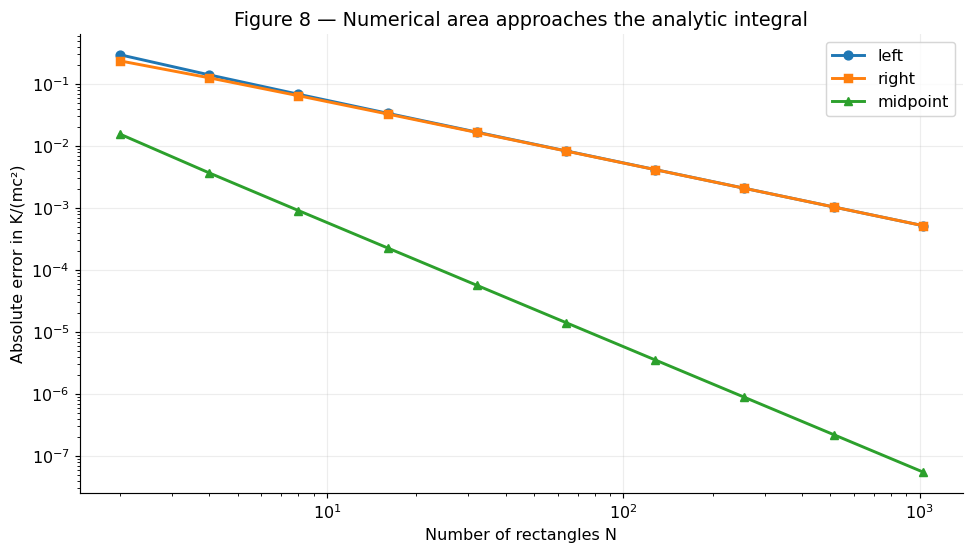

In [10]:
ns = np.array([2, 4, 8, 16, 32, 64, 128, 256, 512, 1024])
fig, ax = plt.subplots()
for kind, marker in [('left','o'), ('right','s'), ('midpoint','^')]:
    errors = [abs(riemann_work(int(n), kind)-exact_K) for n in ns]
    ax.loglog(ns, errors, marker=marker, lw=2, label=kind)
ax.set(xlabel='Number of rectangles N',
       ylabel='Absolute error in K/(mc²)',
       title='Figure 8 — Numerical area approaches the analytic integral')
ax.legend()
save_plot('08_riemann_sum_convergence.png')


## 8. Important distinction: $\int v\,dp$ is not $\int p\,dv$

The product rule gives

$$
d(pv)=p\,dv+v\,dp.
$$

Rearrange:

$$
v\,dp=d(pv)-p\,dv.
$$

Integrate from rest, where $p=v=0$:

$$
K=\int_0^{p_f}v\,dp=v_fp_f-\int_0^{v_f}p\,dv.
$$

Geometrically, the first term $v_fp_f$ is a rectangle, and $\int p\,dv$ is the area under the **momentum versus velocity** curve. Subtracting that area from the rectangle returns kinetic energy. The two areas are not individually equal to one another.

Calculate the second area:

$$
\begin{aligned}
\int_0^{v_f}p\,dv
&=m\int_0^{v_f}\frac{v}{\sqrt{1-v^2/c^2}}\,dv\\[4pt]
&=mc^2\left(1-\frac{1}{\gamma_f}\right).
\end{aligned}
$$

Also,

$$
v_fp_f=\gamma_f m v_f^2
=mc^2\left(\gamma_f-\frac{1}{\gamma_f}\right).
$$

Subtract:

$$
\begin{aligned}
K&=mc^2\left(\gamma_f-\frac1{\gamma_f}\right)
-mc^2\left(1-\frac1{\gamma_f}\right)\\[4pt]
&=(\gamma_f-1)mc^2.
\end{aligned}
$$

This provides a **second independent check of the work integral**, using integration by parts.


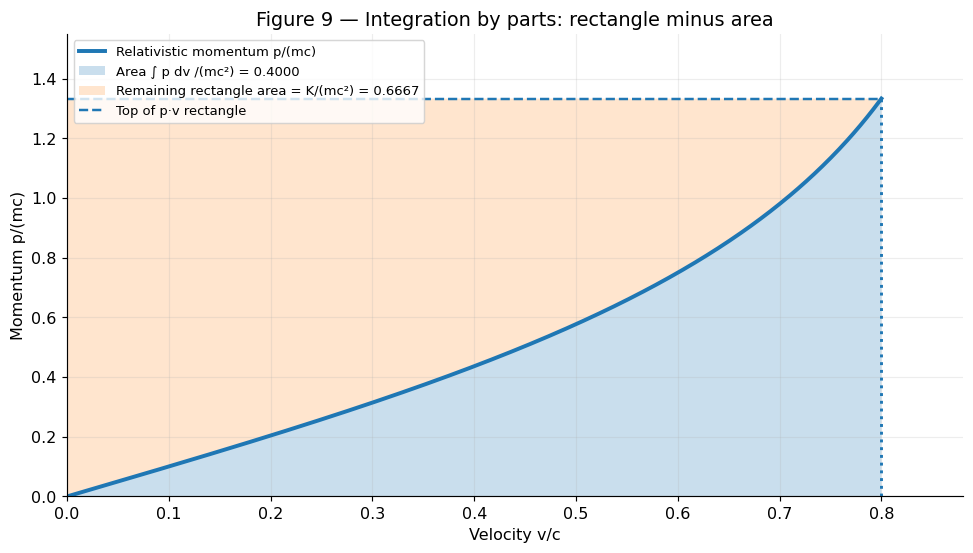

Rectangle vp/(mc²) = 1.066666667
Area ∫p dv/(mc²)    = 0.4
Difference K/(mc²)  = 0.666666667


In [11]:
B2 = np.linspace(0, final_beta, 500)
P2 = gamma(B2)*B2
pmax = gamma(final_beta)*final_beta
rectangle = final_beta*pmax
under_pdv = 1-1/gamma(final_beta)

fig, ax = plt.subplots()
ax.plot(B2, P2, lw=2.7, label='Relativistic momentum p/(mc)')
ax.fill_between(B2, P2, alpha=.24,
                label=f'Area ∫ p dv /(mc²) = {under_pdv:.4f}')
ax.fill_between(B2, P2, pmax, alpha=.2,
                label=f'Remaining rectangle area = K/(mc²) = {exact_K:.4f}')
ax.hlines(pmax, 0, final_beta, ls='--', lw=1.7, label='Top of p·v rectangle')
ax.vlines(final_beta, 0, pmax, ls=':', lw=2)
ax.set(xlabel='Velocity v/c', ylabel='Momentum p/(mc)',
       title='Figure 9 — Integration by parts: rectangle minus area',
       xlim=(0,.88), ylim=(0,1.55))
ax.legend(loc='upper left', fontsize=9)
save_plot('09_integration_by_parts_areas.png')
print('Rectangle vp/(mc²) =', round(rectangle, 9))
print('Area ∫p dv/(mc²)    =', round(under_pdv, 9))
print('Difference K/(mc²)  =', round(rectangle-under_pdv, 9))


## 9. From kinetic energy to TOTAL energy: finding the rest term

At this point we have proved that the **change in energy due to motion**, starting at rest, is

$$
K=(\gamma-1)mc^2.
$$

We may write total energy as

$$
E=E_{\mathrm{rest}}+K.
$$

But the work integral only measures a **difference in energy**. It cannot determine the additive constant $E_{\mathrm{rest}}$ by itself. The identification $E_{\mathrm{rest}}=mc^2$ comes from the Lorentz-covariant energy–momentum structure of special relativity.

### 9.1 Construct the four-momentum

For motion in one spatial dimension, the spacetime coordinates can be written as $(ct,x)$. Dividing both components by proper time gives the four-velocity; multiplying by invariant mass gives the four-momentum:

$$
\begin{aligned}
\text{four-momentum}
&=m\left(\frac{d(ct)}{d\tau},\frac{dx}{d\tau}\right)\\[5pt]
&=m\left(c\frac{dt}{d\tau},\frac{dx}{dt}\frac{dt}{d\tau}\right)\\[5pt]
&=(\gamma mc,\gamma mv).
\end{aligned}
$$

The **spatial** component is exactly the momentum already derived:

$$
p=\gamma mv.
$$

The **temporal** component is energy divided by $c$ (this is the Lorentz-covariant identification, consistent with conservation of energy and momentum):

$$
\frac{E}{c}=\gamma mc.
$$

Multiply both sides by $c$:

$$
E=\gamma mc^2.
$$

At rest $v=0$ and $\gamma=1$, so

$$
E_{\mathrm{rest}}=mc^2.
$$

Consequently,

$$
\begin{aligned}
E-E_{\mathrm{rest}}
&=\gamma mc^2-mc^2\\[4pt]
&=(\gamma-1)mc^2=K,
\end{aligned}
$$

exactly as the work integral requires. The **four-momentum result fixes the reference value** that ordinary integration of work leaves undetermined.

### 9.2 Verify the energy–momentum invariant

Because the spacetime interval is invariant, the four-momentum satisfies

$$
\left(\frac{E}{c}\right)^2-p^2=m^2c^2.
$$

Multiply by $c^2$:

$$
E^2-p^2c^2=m^2c^4.
$$

For positive energy:

$$
E=\sqrt{p^2c^2+m^2c^4}.
$$

Substituting $p=\gamma mv$:

$$
\begin{aligned}
E^2
&=\gamma^2m^2v^2c^2+m^2c^4\\
&=m^2c^4\left(\gamma^2\frac{v^2}{c^2}+1\right)\\
&=m^2c^4\gamma^2,
\end{aligned}
$$

where $1+\gamma^2v^2/c^2=\gamma^2$. Hence $E=\gamma mc^2$ again.

**Scope:** This is the energy of a free massive particle. For a composite body, $m$ is its invariant mass, which already includes internal energy. A massless particle instead has $E=pc$.


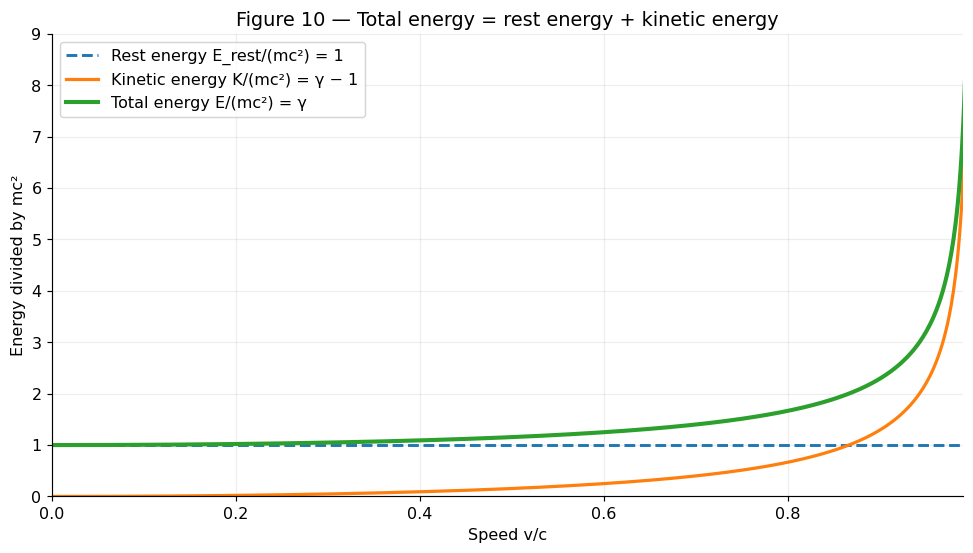

In [12]:
fig, ax = plt.subplots()
ax.plot(beta, np.ones_like(beta), '--', lw=2, label='Rest energy E_rest/(mc²) = 1')
ax.plot(beta, gamma(beta)-1, lw=2.2, label='Kinetic energy K/(mc²) = γ − 1')
ax.plot(beta, gamma(beta), lw=2.8, label='Total energy E/(mc²) = γ')
ax.set(xlabel='Speed v/c', ylabel='Energy divided by mc²',
       title='Figure 10 — Total energy = rest energy + kinetic energy',
       xlim=(0,.99), ylim=(0,9))
ax.legend(loc='upper left')
save_plot('10_total_rest_and_kinetic_energy.png')

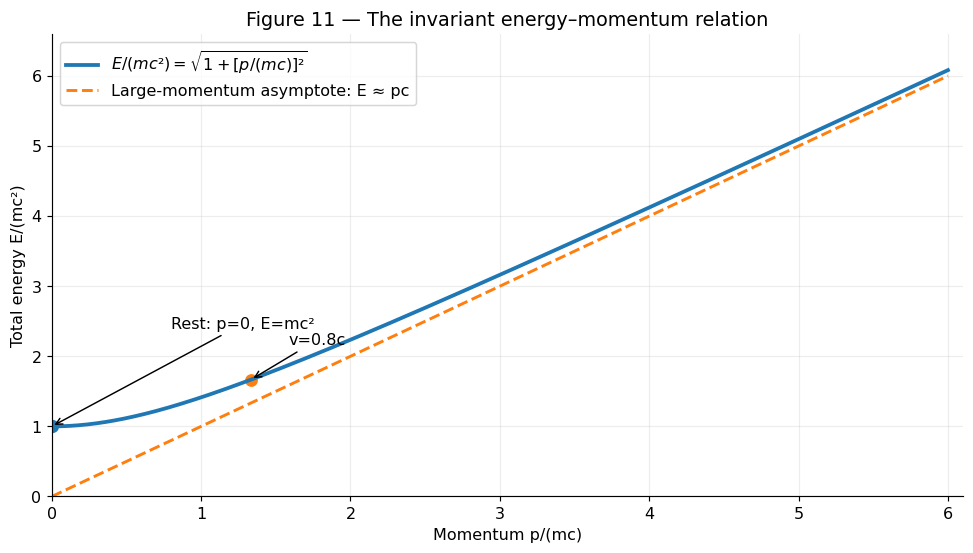

In [13]:
# Plot the positive-energy branch of the mass shell:
# [E/(mc²)]² - [pc/(mc²)]² = 1.
Q = np.linspace(0, 6, 500)     # Q = p/(mc)
E_norm = np.sqrt(1+Q**2)
fig, ax = plt.subplots()
ax.plot(Q, E_norm, lw=2.6, label=r'$E/(mc²)=\sqrt{1+[p/(mc)]²}$')
ax.plot(Q, Q, '--', lw=2, label='Large-momentum asymptote: E ≈ pc')
ax.scatter([0], [1], s=65)
ax.annotate('Rest: p=0, E=mc²', (0,1), xytext=(.8,2.4),
            arrowprops=dict(arrowstyle='->'))
q08 = gamma(.8)*.8
ax.scatter([q08], [gamma(.8)], s=60)
ax.annotate('v=0.8c', (q08, gamma(.8)), xytext=(q08+.25, gamma(.8)+.5),
            arrowprops=dict(arrowstyle='->'))
ax.set(xlabel='Momentum p/(mc)', ylabel='Total energy E/(mc²)',
       title='Figure 11 — The invariant energy–momentum relation',
       xlim=(0,6.1), ylim=(0,6.6))
ax.legend(loc='upper left')
save_plot('11_energy_momentum_invariant.png')


## 10. Differential cross-check: does $E=\gamma mc^2$ reproduce the work law?

Start with our total-energy result:

$$
E=mc^2\gamma.
$$

Differentiate with respect to velocity:

$$
\frac{dE}{dv}=mc^2\frac{d\gamma}{dv}.
$$

Insert $d\gamma/dv=\gamma^3v/c^2$:

$$
\frac{dE}{dv}=m\gamma^3v.
$$

But we also proved $dp/dv=m\gamma^3$, so

$$
\frac{dE}{dv}=v\frac{dp}{dv}.
$$

Multiply through by $dv$:

$$
dE=v\,dp.
$$

At fixed rest mass, $dE=dK$. This reproduces precisely the mechanical work relation from Section 4. Thus the energy formula and momentum formula are **mutually consistent**.

Equivalently, for a force parallel to motion:

$$
\frac{dE}{dt}=v\frac{dp}{dt}=Fv.
$$

This is the relativistic power equation, matching the mechanical definition of power (force times velocity).


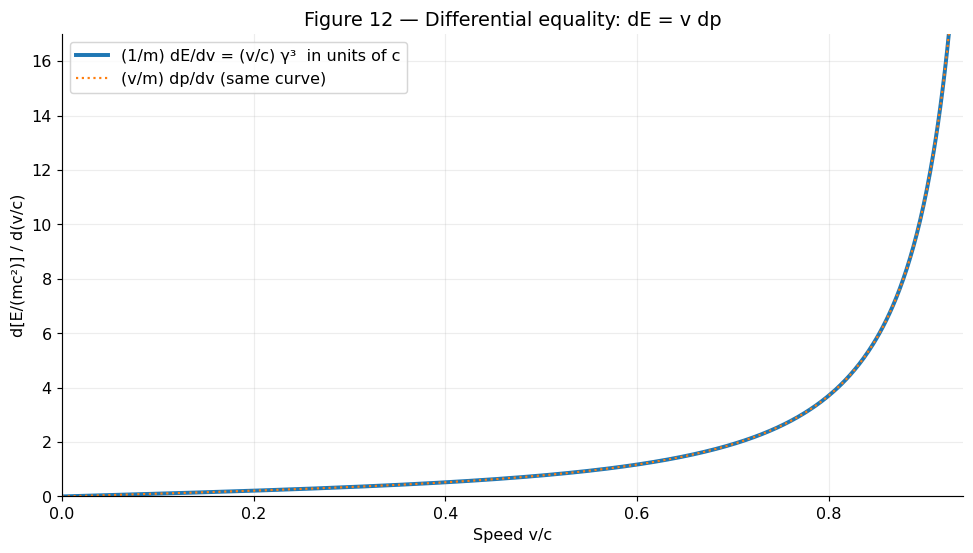

In [14]:
fig, ax = plt.subplots()
ax.plot(beta, beta*gamma(beta)**3, lw=2.7,
        label='(1/m) dE/dv = (v/c) γ³  in units of c')
ax.plot(beta, beta*gamma(beta)**3, ':', lw=1.5,
        label='(v/m) dp/dv (same curve)')
ax.set(xlabel='Speed v/c', ylabel='d[E/(mc²)] / d(v/c)',
       title='Figure 12 — Differential equality: dE = v dp',
       xlim=(0,.94), ylim=(0, 17))
ax.legend()
save_plot('12_energy_and_work_derivative_check.png')


## 11. Worked numerical example: $v=0.8c$

Choose a hypothetical particle or body with $m=1\,\mathrm{kg}$ moving at $v=0.8c$. This is just a pedagogical reference mass; accelerating a macroscopic mass to this speed would require enormous energy.

**Step 1: the Lorentz factor.**

$$
\gamma=\frac{1}{\sqrt{1-(0.8)^2}}
=\frac{1}{0.6}=\frac53\approx1.666667.
$$

**Step 2: relativistic momentum.**

$$
p=\gamma mv=\frac53m(0.8c)=\frac43mc.
$$

**Step 3: kinetic energy from the work integral.**

$$
K=(\gamma-1)mc^2=\frac23mc^2.
$$

**Step 4: rest energy.**

$$
E_{\mathrm{rest}}=mc^2.
$$

**Step 5: total energy.**

$$
E=E_{\mathrm{rest}}+K
=\left(1+\frac23\right)mc^2
=\frac53mc^2.
$$

The following code evaluates all quantities using the exact SI speed of light and verifies their relationships.


In [15]:
m = 1.0                    # kg
v = 0.8 * c               # m/s
g = float(gamma(v/c))
p = g * m * v
K = (g - 1) * m * c**2
E_rest = m * c**2
E = g * m * c**2
K_newton = 0.5*m*v*v

print(f'm                  = {m:.1f} kg')
print(f'v                  = {v:,.1f} m/s = {v/c:.1f} c')
print(f'gamma              = {g:.9f}')
print(f'p                  = {p:.6e} kg m/s')
print(f'p/(mc)             = {p/(m*c):.9f}')
print(f'K relativistic     = {K:.6e} J')
print(f'K Newtonian        = {K_newton:.6e} J')
print(f'Rest energy        = {E_rest:.6e} J')
print(f'Total energy       = {E:.6e} J')
print(f'E/(mc²)            = {E/E_rest:.9f}')
print(f'(E²-p²c²)/(m²c⁴) = {(E*E-p*p*c*c)/(m*m*c**4):.9f}')

assert np.isclose(E, E_rest+K)
assert np.isclose(E*E-p*p*c*c, m*m*c**4, rtol=1e-12)

m                  = 1.0 kg
v                  = 239,833,966.4 m/s = 0.8 c
gamma              = 1.666666667
p                  = 3.997233e+08 kg m/s
p/(mc)             = 1.333333333
K relativistic     = 5.991701e+16 J
K Newtonian        = 2.876017e+16 J
Rest energy        = 8.987552e+16 J
Total energy       = 1.497925e+17 J
E/(mc²)            = 1.666666667
(E²-p²c²)/(m²c⁴) = 1.000000000


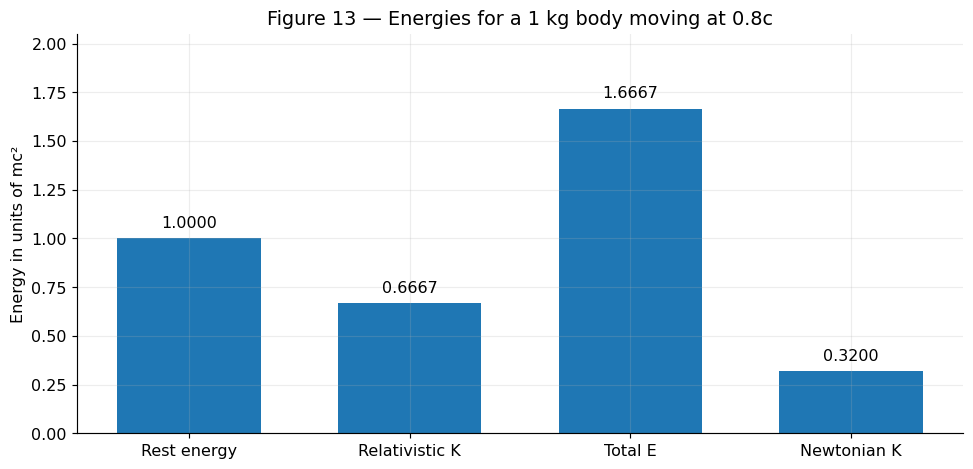

In [16]:
values = [1.0, g-1, g, 0.5*(v/c)**2]
labels = ['Rest energy', 'Relativistic K', 'Total E', 'Newtonian K']
fig, ax = plt.subplots(figsize=(9.4,4.6))
bars = ax.bar(labels, values, width=.65)
for bar, val in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, val+.04, f'{val:.4f}',
            ha='center', va='bottom')
ax.set(ylabel='Energy in units of mc²',
       title='Figure 13 — Energies for a 1 kg body moving at 0.8c',
       ylim=(0,2.05))
save_plot('13_example_energy_bars.png')


## 12. Newton's kinetic energy emerges at small speeds (Taylor series)

The Lorentz factor has the binomial series

$$
\gamma=\frac{1}{\sqrt{1-v^2/c^2}}
=1+\frac12\frac{v^2}{c^2}
+\frac38\frac{v^4}{c^4}
+\frac5{16}\frac{v^6}{c^6}
+\frac{35}{128}\frac{v^8}{c^8}+\cdots,
\qquad |v|<c.
$$

Subtract $1$ and multiply by $mc^2$:

$$
\begin{aligned}
K&=(\gamma-1)mc^2\\[4pt]
&=\frac12mv^2
+\frac38\frac{mv^4}{c^2}
+\frac5{16}\frac{mv^6}{c^4}
+\frac{35}{128}\frac{mv^8}{c^6}+\cdots.
\end{aligned}
$$

When $v\ll c$, the higher powers of $v/c$ are tiny, giving the classical limit:

$$
K\approx\tfrac12mv^2.
$$

The exact coefficient of $(v/c)^{2n}$ in $\gamma$ is

$$
a_n=\frac{\binom{2n}{n}}{4^n}\quad\text{for }n=0,1,2,\ldots
$$

The $n=0$ term equals $1$; it cancels when computing $\gamma-1$. This is a Taylor/binomial **expansion of an already established relativistic formula**, not a replacement for the physical argument that led to it.


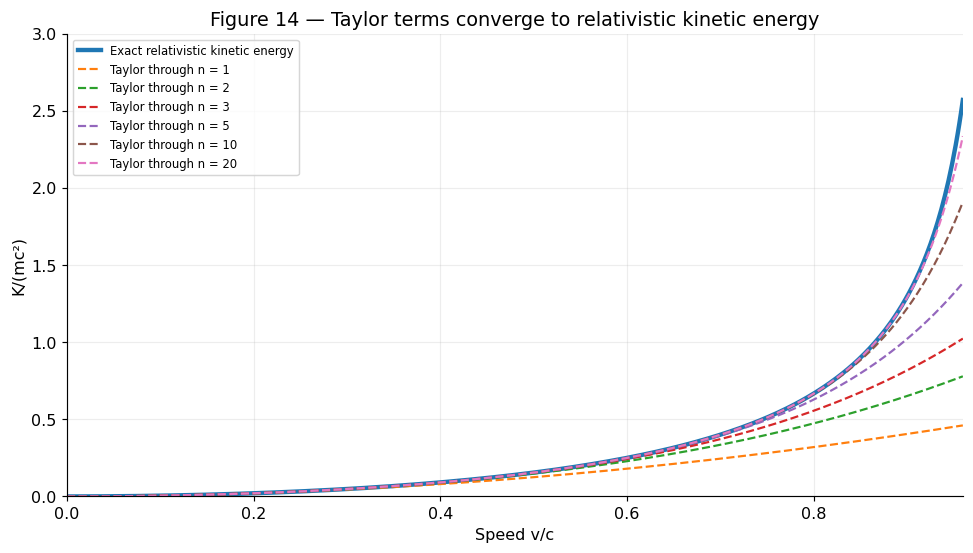

 n  coefficient a_n = C(2n,n)/4^n
 0         1 / 1        = 1.0000000000
 1         2 / 4        = 0.5000000000
 2         6 / 16       = 0.3750000000
 3        20 / 64       = 0.3125000000
 4        70 / 256      = 0.2734375000
 5       252 / 1024     = 0.2460937500
 6       924 / 4096     = 0.2255859375
 7      3432 / 16384    = 0.2094726562
 8     12870 / 65536    = 0.1963806152


In [17]:
from math import comb

def series_kinetic(beta_values, highest_power_n):
    # Return the Taylor approximation K/(mc²), keeping n=1..highest_power_n.
    beta_values = np.asarray(beta_values)
    out = np.zeros_like(beta_values, dtype=float)
    for n in range(1, highest_power_n+1):
        coeff = comb(2*n,n) / 4**n
        out = out + coeff*beta_values**(2*n)
    return out

bs = np.linspace(0,.96,500)
fig, ax = plt.subplots()
ax.plot(bs, gamma(bs)-1, lw=3, label='Exact relativistic kinetic energy')
for order in [1,2,3,5,10,20]:
    ax.plot(bs, series_kinetic(bs,order), '--', lw=1.5, label=f'Taylor through n = {order}')
ax.set(xlabel='Speed v/c', ylabel='K/(mc²)',
       title='Figure 14 — Taylor terms converge to relativistic kinetic energy',
       xlim=(0,.96), ylim=(0,3))
ax.legend(fontsize=8)
save_plot('14_taylor_approximations.png')

print(' n  coefficient a_n = C(2n,n)/4^n')
for n in range(0,9):
    print(f'{n:2d}    {comb(2*n,n):6d} / {4**n:<8d} = {comb(2*n,n)/4**n:.10f}')

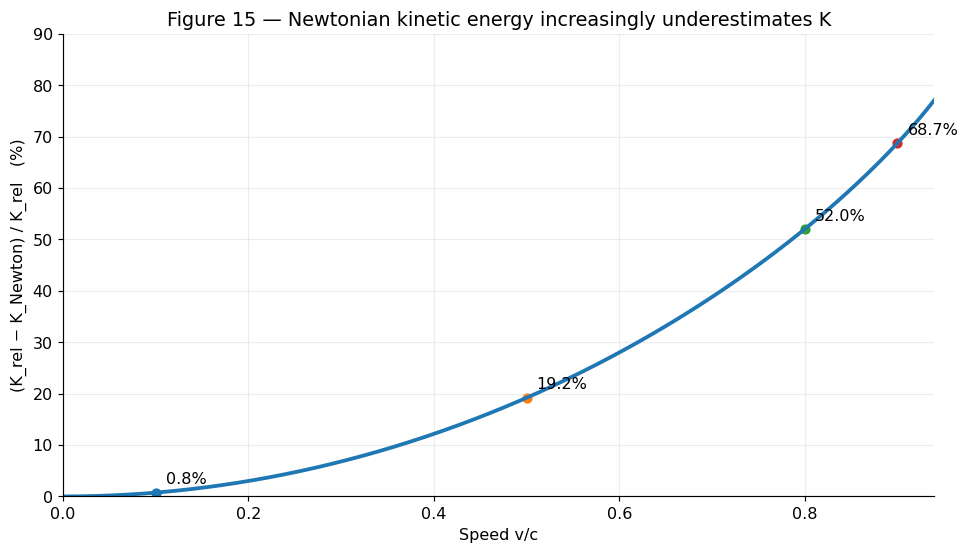

In [18]:
bs = np.linspace(0,.94,500)
K_exact = gamma(bs)-1
K_classical = .5*bs**2
relative = np.full_like(bs, np.nan)
relative[1:] = (K_exact[1:] - K_classical[1:]) / K_exact[1:]
fig, ax = plt.subplots()
ax.plot(bs[1:], 100*relative[1:], lw=2.6)
for b in [.1, .5, .8, .9]:
    err = 100*(gamma(b)-1-.5*b*b)/(gamma(b)-1)
    ax.scatter([b],[err])
    ax.annotate(f'{err:.1f}%', (b,err), xytext=(7,6), textcoords='offset points')
ax.set(xlabel='Speed v/c', ylabel='(K_rel − K_Newton) / K_rel   (%)',
       title='Figure 15 — Newtonian kinetic energy increasingly underestimates K',
       xlim=(0,.94), ylim=(0,90))
save_plot('15_newtonian_error.png')

## 13. Summary table over a range of velocities

The next table reports dimensionless results. Multiplying $p/(mc)$ by $mc$ gives momentum; multiplying $K/(mc^2)$ or $E/(mc^2)$ by $mc^2$ gives energy for any chosen nonzero rest mass.

In [19]:
print(f'{"v/c":>7} | {"γ":>11} | {"p/(mc)":>12} | {"K/(mc²)":>12} | {"E/(mc²)":>12}')
print('-'*69)
for b in [0,0.1,0.2,0.5,0.8,0.9,0.95,0.99]:
    g=float(gamma(b))
    print(f'{b:7.2f} | {g:11.6f} | {g*b:12.6f} | {g-1:12.6f} | {g:12.6f}')

    v/c |           γ |       p/(mc) |      K/(mc²) |      E/(mc²)
---------------------------------------------------------------------
   0.00 |    1.000000 |     0.000000 |     0.000000 |     1.000000
   0.10 |    1.005038 |     0.100504 |     0.005038 |     1.005038
   0.20 |    1.020621 |     0.204124 |     0.020621 |     1.020621
   0.50 |    1.154701 |     0.577350 |     0.154701 |     1.154701
   0.80 |    1.666667 |     1.333333 |     0.666667 |     1.666667
   0.90 |    2.294157 |     2.064742 |     1.294157 |     2.294157
   0.95 |    3.202563 |     3.042435 |     2.202563 |     3.202563
   0.99 |    7.088812 |     7.017924 |     6.088812 |     7.088812



## 14. Final derivation on one page

1. **Time dilation and the Lorentz factor**

   $$
   d\tau=dt\sqrt{1-v^2/c^2},\qquad \frac{dt}{d\tau}=\gamma.
   $$

2. **Spatial four-momentum / relativistic momentum**

   $$
   p=m\frac{dx}{d\tau}=m\frac{dx}{dt}\frac{dt}{d\tau}=\gamma mv.
   $$

3. **Mechanical work and momentum**

   $$
   dK=F\,dx=\frac{dp}{dt}(v\,dt)=v\,dp.
   $$

4. **Differentiate $\gamma$ and $p$**

   $$
   \frac{d\gamma}{dv}=\frac{\gamma^3v}{c^2},
   \qquad \frac{dp}{dv}=m\gamma^3.
   $$

5. **Substitute into the work relation**

   $$
   dK=v\frac{dp}{dv}\,dv
   =mv\gamma^3\,dv=mc^2\,d\gamma.
   $$

6. **Integrate from rest to speed $v$**

   $$
   K=mc^2\int_1^{\gamma}d\gamma
   =(\gamma-1)mc^2.
   $$

7. **Use the time component of four-momentum to fix rest energy**

   $$
   \frac{E}{c}=m\frac{d(ct)}{d\tau}=\gamma mc
   \quad\Longrightarrow\quad E=\gamma mc^2.
   $$

8. **Check consistency**

   $$
   E_{\mathrm{rest}}=mc^2,\qquad
   E-E_{\mathrm{rest}}=(\gamma-1)mc^2=K,
   $$

   $$
   E^2-p^2c^2=m^2c^4,\qquad dE=v\,dp.
   $$

### Central conceptual distinction

- $K=(\gamma-1)mc^2$ follows from **the relativistic momentum formula plus the work–energy theorem**.
- $E=\gamma mc^2$ describes **total energy**. Its rest-energy term is established by the energy component of **four-momentum**, not by the work integral alone.
- $E=mc^2$ at rest is the special case $v=0$.
- Momentum and energy both grow without bound as a massive object's speed approaches $c$, which is why finite work cannot accelerate it to the speed of light.

### Mathematical checks performed by this notebook

The notebook verifies the $v=0.8c$ example, the energy–momentum invariant, the identity $E=K+mc^2$, and the numerical Riemann-sum limit of $\int v\,dp$. It produces and saves fifteen figures.
